# Classical AI: Fuzzy Logic and Expert Systems

> **Who is this for?** Beginners who know Python basics and want to see two of the most successful "classical" AI
> technologies, and students preparing for exams that cover fuzzy sets, Mamdani inference and rule-based systems.
>
> **What you will learn**
> - crisp vs. fuzzy sets, membership functions (triangular, trapezoidal, Gaussian), linguistic variables and hedges
> - fuzzy AND / OR / NOT with min / max and with other t-norms and t-conorms
> - fuzzy IF-THEN rules and **Mamdani inference** step by step (fuzzification, rule evaluation, aggregation,
>   defuzzification by centroid and mean of maximum), built from scratch for a tipping controller, plus its control surface
> - a short look at **Sugeno** inference
> - **rule-based expert systems**: knowledge base, inference engine, working memory, explanation facility; a small car
>   diagnosis system with forward chaining, conflict resolution, backward chaining and "why / how" explanations
> - MYCIN-style **certainty factors** (historical)
> - strengths, limits, and where these ideas are still used today
>
> **Prerequisites**
> - Python basics: [`../../01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb)
> - Maths symbols: [`../../14_Mathematics/00_start_here_math_notation_bridge.ipynb`](../../14_Mathematics/00_start_here_math_notation_bridge.ipynb)
> - Recommended: [`07_knowledge_representation_and_logic.ipynb`](07_knowledge_representation_and_logic.ipynb) (rules, forward and backward chaining in logic), and [`09_uncertain_knowledge_and_reasoning.ipynb`](09_uncertain_knowledge_and_reasoning.ipynb)
>   (for the contrast between degrees of belief and degrees of truth)
>
> **Time needed:** about 2 to 2.5 hours.
>
> **Runs on:** CPU, no API key, no internet. Only `numpy`, `pandas` and `matplotlib`.
>
> **Optional track:** this notebook is part of the *university-level fundamentals track*. It is not required for the
> main path of the repo, but it is recommended for BS/MS AI students and for interview preparation.

## Explained simply

People use vague words all the time: "warm", "tall", "a bit too fast". **Fuzzy logic** lets a computer use such words
by giving each one a degree from 0 to 1 instead of a hard yes/no, so 24 °C can be "mostly warm and a little hot". A fuzzy
controller turns simple human rules ("if the room is hot, run the fan fast") into a smooth, precise number. An **expert
system** stores the know-how of a specialist as many IF-THEN rules and applies them to a new case, step by step. Its big
strength is that it can explain itself: it can tell you which rules and facts led to its answer.

- **Everyday example 1:** a "fuzzy logic" rice cooker or washing machine adjusts heat or spin gradually ("the water is
  quite dirty, so wash a bit longer") instead of switching between a few fixed settings.
- **Everyday example 2:** a car mechanic's checklist ("if the engine does not turn and the lights are dim, check the
  battery") is exactly the kind of rule an expert system stores; so are a bank's rules for approving a loan.

**Tiny concrete example.** Say "warm" goes up from 0 at 15 °C to 1 at 25 °C. At 20 °C the room is warm to degree
(20 − 15) / (25 − 15) = **0.5**. With the rule "IF warm THEN fan speed is medium (50%)", the fan runs at about half of
"medium" strength instead of jumping between off and on.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Fuzzy set | a word with degrees, not a yes/no box | thermostats, camera autofocus, washing machines |
| Mamdani controller | vague rules in, one precise number out | fan, heater and train speed control |
| Expert system | a specialist's IF-THEN rules plus an engine that applies and explains them | loan approval, insurance rules, troubleshooting guides |

## Table of contents
**Part 1: Fuzzy logic**
1. Crisp sets vs. fuzzy sets
2. Membership functions
3. Linguistic variables and hedges
4. Fuzzy operations: complement, t-norms and t-conorms
5. Fuzzy rules and implication
6. Mamdani inference step by step: a tipping controller
7. The control surface, and Sugeno inference

**Part 2: Expert systems**

8. Architecture of a rule-based expert system
9. Forward chaining with conflict resolution
10. Explanations: "how" and "why" (with backward chaining)
11. Certainty factors (MYCIN, historical)
12. Strengths, limits, and where these systems are used today

In [1]:
# Setup
import itertools, math, random, time               # standard library helpers
from collections import defaultdict                 # dict with default values
import numpy as np                                  # numeric arrays
import pandas as pd                                 # tables
import matplotlib.pyplot as plt                     # plots

random.seed(0); np.random.seed(0)                   # reproducible results
pd.set_option("display.precision", 3)               # 3 decimals in tables
pd.set_option("display.max_colwidth", 120)          # show long text in full
pd.set_option("display.width", 200)                 # wide tables on one line
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.4.6 | pandas 2.3.3


---
# Part 1: Fuzzy logic

## 1. Crisp sets vs. fuzzy sets

> 💡 **In plain English:** instead of "in or out", every item belongs to a group by some degree between 0 and 1.

**Intuition.** Is a person who is 179 cm tall "tall"? With an ordinary (crisp) rule like "tall means at least 180 cm",
179 cm is *not tall* and 180 cm *is tall*. One centimetre flips the answer completely, which is not how people think.
Humans use words like *tall*, *warm*, *fast*, *cheap* that fade gradually.

**Definitions.**
- A **crisp set** $A$ of a universe $X$ is described by a characteristic function $\chi_A : X \to \{0, 1\}$: every
  element is either in or out.
- A **fuzzy set** $A$ (Lotfi Zadeh, 1965) is described by a **membership function** $\mu_A : X \to [0, 1]$.
  $\mu_A(x)$ is the **degree of membership** of $x$ in $A$: 0 = not at all, 1 = fully, in between = partly.
- The **support** of $A$ is $\{x : \mu_A(x) > 0\}$, the **core** is $\{x : \mu_A(x) = 1\}$, and the **$\alpha$-cut** is
  $\{x : \mu_A(x) \ge \alpha\}$ (a crisp set).

**By hand.** Let "tall" rise linearly from 0 at 165 cm to 1 at 185 cm. Then
$\mu_{tall}(179) = (179 - 165)/(185 - 165) = 0.7$ and $\mu_{tall}(181) = 0.8$: nearly the same, as common sense says.

> ⚠️ **Common mistake: a membership degree is not a probability.** $\mu_{tall}(179) = 0.7$ does not mean "70% chance the
> person is tall". The height is known exactly; the *word* "tall" is vague. Probability (previous notebook) models
> uncertainty about facts; fuzzy logic models vagueness of concepts. Membership degrees of different sets do **not** have to
> add up to 1.

179 cm: crisp tall = 0,  fuzzy tall = 0.70
180 cm: crisp tall = 1,  fuzzy tall = 0.75
181 cm: crisp tall = 1,  fuzzy tall = 0.80


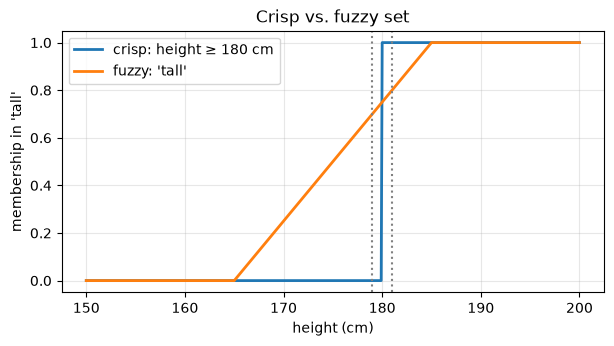

In [2]:
heights = np.linspace(150, 200, 501)                                  # universe of discourse in cm
crisp_tall = (heights >= 180).astype(float)                            # characteristic function: 0 or 1
fuzzy_tall = np.clip((heights - 165) / (185 - 165), 0, 1)              # linear ramp from 165 to 185 cm

for h in (179, 180, 181):
    print(f"{h} cm: crisp tall = {int(h >= 180)},  fuzzy tall = {np.clip((h - 165) / 20, 0, 1):.2f}")

plt.figure(figsize=(7, 3.4))
plt.plot(heights, crisp_tall, label="crisp: height ≥ 180 cm", lw=2)
plt.plot(heights, fuzzy_tall, label="fuzzy: 'tall'", lw=2)
plt.axvline(179, color="grey", ls=":"); plt.axvline(181, color="grey", ls=":")
plt.xlabel("height (cm)"); plt.ylabel("membership in 'tall'"); plt.title("Crisp vs. fuzzy set")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**What just happened?** The crisp set jumps from 0 to 1 at exactly 180 cm, so 179 cm and 181 cm are treated as opposites.
The fuzzy set gives 0.70 and 0.80: a smooth change for a small change in height. Evaluating a membership function is
$O(1)$ per point.

## 2. Membership functions

> 💡 **In plain English:** simple shapes (triangles, trapezoids, bells) that say how much a value fits a word.

The three most common shapes (all used in industrial controllers):

| Shape | Parameters | Formula | Typical use |
|---|---|---|---|
| **Triangular** | $a \le b \le c$ | $\max\big(\min(\frac{x-a}{b-a}, \frac{c-x}{c-b}), 0\big)$ | simple, cheap, most common |
| **Trapezoidal** | $a \le b \le c \le d$ | $\max\big(\min(\frac{x-a}{b-a}, 1, \frac{d-x}{d-c}), 0\big)$ | a flat core: "anything from b to c is fully X"; shoulders at the edges of the range |
| **Gaussian** | centre $m$, width $\sigma$ | $\exp\big(-\frac{(x-m)^2}{2\sigma^2}\big)$ | smooth (differentiable), used in neuro-fuzzy systems |

**By hand.** Triangle $(2, 5, 8)$ at $x = 4$: $\min((4-2)/3, (8-4)/3) = \min(0.667, 1.333) = 0.667$.
Gaussian $(m = 5, \sigma = 1.5)$ at $x = 3$: $\exp(-4/4.5) = 0.411$.

When $a = b$ (or $c = d$) the shape becomes a **shoulder**: it stays at 1 up to the edge. Our functions handle this
case without dividing by zero.

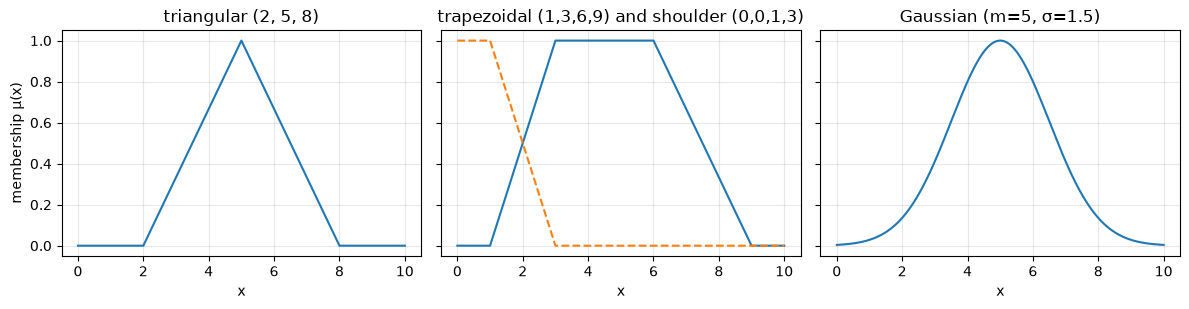

In [3]:
def trimf(x, a, b, c):
    # triangular membership function with feet a, c and peak b (a <= b <= c); a == b or b == c gives a shoulder
    x = np.asarray(x, dtype=float)
    left = np.ones_like(x) if b == a else (x - a) / (b - a)          # rising edge (or flat if a == b)
    right = np.ones_like(x) if c == b else (c - x) / (c - b)         # falling edge (or flat if b == c)
    y = np.clip(np.minimum(left, right), 0.0, 1.0)
    return np.where((x < a) | (x > c), 0.0, y)                        # zero outside [a, c]

def trapmf(x, a, b, c, d):
    # trapezoidal membership function: rises a->b, flat 1 on [b, c], falls c->d
    x = np.asarray(x, dtype=float)
    left = np.ones_like(x) if b == a else (x - a) / (b - a)
    right = np.ones_like(x) if d == c else (d - x) / (d - c)
    y = np.clip(np.minimum(np.minimum(left, right), 1.0), 0.0, 1.0)
    return np.where((x < a) | (x > d), 0.0, y)

def gaussmf(x, m, sigma):
    # Gaussian membership function with centre m and width sigma
    x = np.asarray(x, dtype=float)
    return np.exp(-((x - m) ** 2) / (2 * sigma ** 2))

assert abs(trimf(4, 2, 5, 8) - 2 / 3) < 1e-12 and abs(gaussmf(3, 5, 1.5) - math.exp(-4 / 4.5)) < 1e-12
assert trimf(5, 2, 5, 8) == 1 and trimf(1, 2, 5, 8) == 0 and trapmf(0, 0, 0, 1, 3) == 1   # peak, outside, shoulder
assert trapmf(2, 0, 0, 1, 3) == 0.5 and trimf(0, 0, 0, 10) == 1 and trimf(-1, 0, 0, 10) == 0

x = np.linspace(0, 10, 1001)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
axes[0].plot(x, trimf(x, 2, 5, 8)); axes[0].set_title("triangular (2, 5, 8)")
axes[1].plot(x, trapmf(x, 1, 3, 6, 9)); axes[1].plot(x, trapmf(x, 0, 0, 1, 3), "--"); axes[1].set_title("trapezoidal (1,3,6,9) and shoulder (0,0,1,3)")
axes[2].plot(x, gaussmf(x, 5, 1.5)); axes[2].set_title("Gaussian (m=5, σ=1.5)")
for ax in axes:
    ax.set_xlabel("x"); ax.grid(alpha=0.3)
axes[0].set_ylabel("membership μ(x)"); plt.tight_layout(); plt.show()

**What just happened?** We wrote the three standard membership functions with numpy so they work on whole arrays at
once, checked them against the hand calculations (0.667 and 0.411) and plotted them. The dashed curve is a *left shoulder*:
fully 1 up to $x = 1$, then falling to 0 at $x = 3$.

## 3. Linguistic variables and hedges

> 💡 **In plain English:** a quantity described with words (cold, warm, hot), and words like "very" that sharpen or soften them.

**Definition.** A **linguistic variable** (Zadeh, 1975) is a variable whose values are words. It has a name
(`temperature`), a **universe of discourse** (0 to 40 °C), a set of **linguistic terms** (`cold`, `warm`, `hot`), and one
membership function per term. Neighbouring terms usually **overlap**, so 21 °C can be "a bit warm and a bit hot".

**Hedges** are words that modify a term, defined as operations on its membership function (Zadeh's classic choices):

| Hedge | Operation | Effect |
|---|---|---|
| **very** A | $\mu_A(x)^2$ | concentration: narrower, stricter |
| **extremely** A | $\mu_A(x)^3$ | even stricter |
| **somewhat / more or less** A | $\sqrt{\mu_A(x)}$ | dilation: wider, more tolerant |
| **not** A | $1 - \mu_A(x)$ | complement |

**By hand.** If $\mu_{hot}(27) = 0.625$ then $\mu_{very\ hot}(27) = 0.391$ and $\mu_{somewhat\ hot}(27) = 0.791$.

at 27.0 °C: {'cold': 0.0, 'warm': 0.125, 'hot': 0.625}
{'very hot': 0.391, 'extremely hot': 0.244, 'somewhat hot': 0.791, 'not hot': 0.375}


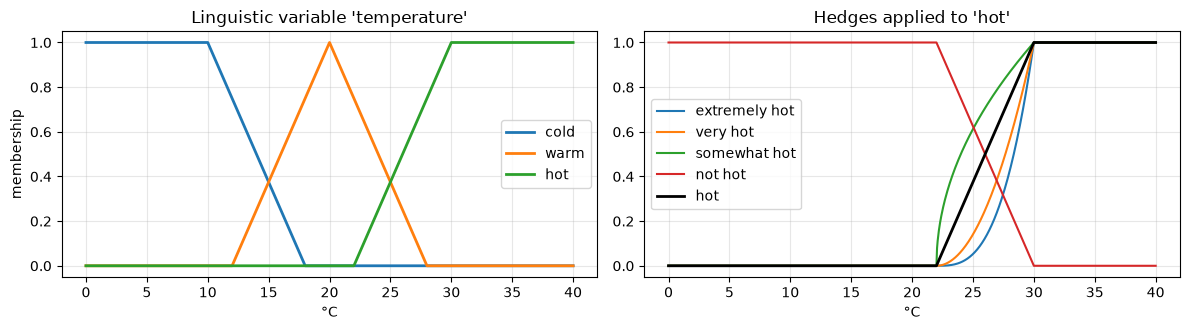

In [4]:
temp = np.linspace(0, 40, 801)                                         # universe of discourse in °C
TEMP_TERMS = {
    "cold": lambda t: trapmf(t, 0, 0, 10, 18),                          # left shoulder
    "warm": lambda t: trimf(t, 12, 20, 28),
    "hot":  lambda t: trapmf(t, 22, 30, 40, 40),                        # right shoulder
}
HEDGES = {"very": lambda m: m ** 2, "extremely": lambda m: m ** 3,
          "somewhat": lambda m: np.sqrt(m), "not": lambda m: 1 - m}

t0 = 27.0
print(f"at {t0} °C:", {name: round(float(f(t0)), 3) for name, f in TEMP_TERMS.items()})
mu_hot = TEMP_TERMS["hot"](t0)
print({f"{h} hot": round(float(op(mu_hot)), 3) for h, op in HEDGES.items()})
assert abs(mu_hot - 0.625) < 1e-12

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for name, f in TEMP_TERMS.items():
    axes[0].plot(temp, f(temp), label=name, lw=2)
axes[0].set_title("Linguistic variable 'temperature'"); axes[0].set_xlabel("°C"); axes[0].set_ylabel("membership")
axes[0].legend(); axes[0].grid(alpha=0.3)
for h in ["extremely", "very", "somewhat", "not"]:
    axes[1].plot(temp, HEDGES[h](TEMP_TERMS["hot"](temp)), label=f"{h} hot")
axes[1].plot(temp, TEMP_TERMS["hot"](temp), "k", lw=2, label="hot")
axes[1].set_title("Hedges applied to 'hot'"); axes[1].set_xlabel("°C"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**What just happened?** At 27 °C the temperature is partly `warm` (0.125) and partly `hot` (0.625), and not `cold` at
all: the degrees do not sum to 1, and they do not need to. The right plot shows how hedges reshape `hot`: `very` and
`extremely` make it stricter (a lower degree for the same temperature), `somewhat` makes it more tolerant.

## 4. Fuzzy operations: complement, t-norms and t-conorms

> 💡 **In plain English:** fuzzy versions of AND, OR and NOT, and the several sensible ways to define them.

For crisp sets, AND = intersection, OR = union, NOT = complement. Zadeh's original fuzzy versions are:

$$\mu_{A \cap B}(x) = \min(\mu_A(x), \mu_B(x)), \qquad \mu_{A \cup B}(x) = \max(\mu_A(x), \mu_B(x)), \qquad \mu_{\lnot A}(x) = 1 - \mu_A(x)$$

More generally, any function $T : [0,1]^2 \to [0,1]$ that is **commutative**, **associative**, **monotone** (never
decreases when an input increases) and has **1 as identity** ($T(a, 1) = a$) is a **t-norm** (triangular norm) and can be
used as fuzzy AND. Its dual $S(a, b) = 1 - T(1-a, 1-b)$ is a **t-conorm** (fuzzy OR, with identity 0). This duality is
De Morgan's law.

| t-norm (AND) | $T(a, b)$ | dual t-conorm (OR) | $S(a, b)$ |
|---|---|---|---|
| minimum (Zadeh) | $\min(a, b)$ | maximum | $\max(a, b)$ |
| algebraic product | $a \cdot b$ | probabilistic sum | $a + b - ab$ |
| Łukasiewicz (bounded difference) | $\max(0, a + b - 1)$ | bounded sum | $\min(1, a + b)$ |
| drastic | $b$ if $a = 1$; $a$ if $b = 1$; else 0 | drastic sum | $b$ if $a = 0$; $a$ if $b = 0$; else 1 |

Every t-norm lies between the drastic t-norm (smallest) and the minimum (largest): $T_{drastic} \le T_{Luk} \le T_{prod} \le \min$.

**By hand** with $a = 0.7$, $b = 0.6$: min = 0.6, product = 0.42, Łukasiewicz = 0.3, drastic = 0.

> 🎓 **Exam / interview tip.** With min/max, fuzzy logic breaks two classical laws: $\mu_{A \land \lnot A} = \min(\mu, 1-\mu)$
> can be up to 0.5 (no law of non-contradiction) and $\mu_{A \lor \lnot A}$ can be as low as 0.5 (no law of excluded
> middle). With the Łukasiewicz pair both laws hold again, but then idempotence ($A \land A = A$) fails. No t-norm keeps
> everything; this is a theorem, not a bug.

             AND  T(0.7, 0.6)  OR   S(0.7, 0.6)
min                      0.60              0.70
product                  0.42              0.88
Lukasiewicz              0.30              1.00
drastic                  0.00              1.00
t-norm axioms and the ordering drastic <= Lukasiewicz <= product <= min verified on a grid
A AND NOT A with min: 0.4  | with Lukasiewicz: 0.0
A AND A     with min: 0.6  | with Lukasiewicz: 0.2


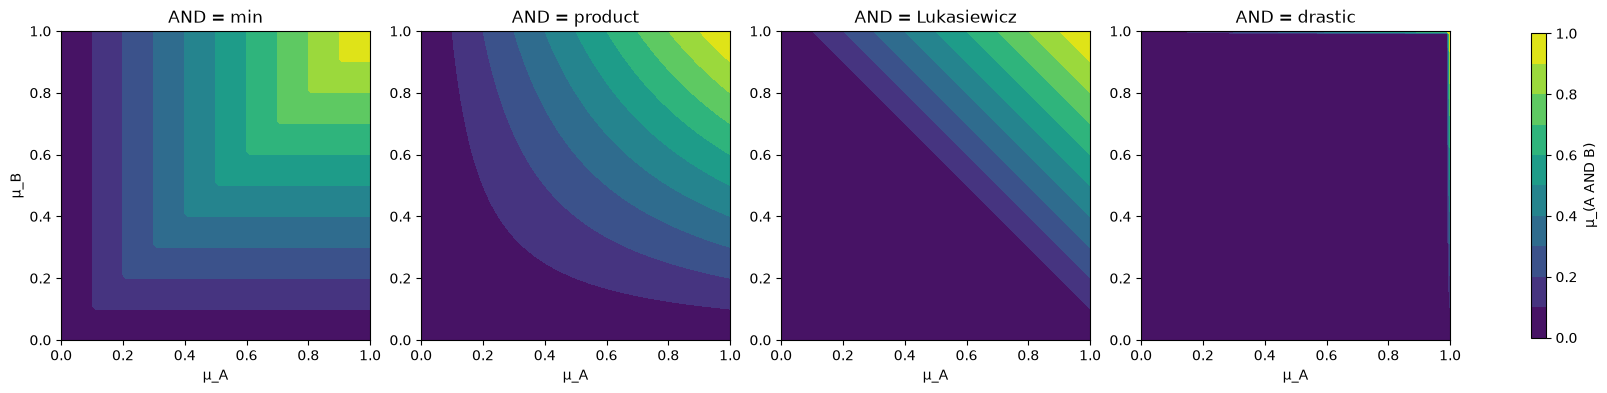

In [5]:
T_NORMS = {
    "min":         lambda a, b: np.minimum(a, b),
    "product":     lambda a, b: a * b,
    "Lukasiewicz": lambda a, b: np.maximum(0.0, a + b - 1.0),
    "drastic":     lambda a, b: np.where(a == 1.0, b, np.where(b == 1.0, a, 0.0)),
}
def dual_conorm(T):
    # De Morgan: S(a, b) = 1 - T(1 - a, 1 - b)
    return lambda a, b: 1.0 - T(1.0 - a, 1.0 - b)
T_CONORMS = {name: dual_conorm(T) for name, T in T_NORMS.items()}

a, b = 0.7, 0.6
print(pd.DataFrame({"AND  T(0.7, 0.6)": {n: float(T(np.float64(a), np.float64(b))) for n, T in T_NORMS.items()},
                    "OR   S(0.7, 0.6)": {n: float(S(np.float64(a), np.float64(b))) for n, S in T_CONORMS.items()}}).round(3))

# Verify the t-norm axioms numerically on a grid (including the exact values 0 and 1)
g = np.round(np.linspace(0, 1, 11), 10)
A_, B_, C_ = np.meshgrid(g, g, g, indexing="ij")
for name, T in T_NORMS.items():
    assert np.allclose(T(A_, B_), T(B_, A_)), name                              # commutative
    assert np.allclose(T(A_, T(B_, C_)), T(T(A_, B_), C_)), name                # associative
    assert np.allclose(T(A_, np.ones_like(A_)), A_), name                      # identity element 1
    assert np.all(T(A_, B_) <= T(A_, np.maximum(B_, C_)) + 1e-12), name        # monotone in the second argument
    assert np.allclose(T_CONORMS[name](A_, np.zeros_like(A_)), A_), name       # conorm identity element 0
assert np.all(T_NORMS["drastic"](A_, B_) <= T_NORMS["Lukasiewicz"](A_, B_) + 1e-12)
assert np.all(T_NORMS["Lukasiewicz"](A_, B_) <= T_NORMS["product"](A_, B_) + 1e-12)
assert np.all(T_NORMS["product"](A_, B_) <= T_NORMS["min"](A_, B_) + 1e-12)
print("t-norm axioms and the ordering drastic <= Lukasiewicz <= product <= min verified on a grid")

mu = 0.6
print(f"A AND NOT A with min: {min(mu, 1 - mu):.1f}  | with Lukasiewicz: {max(0, mu + (1 - mu) - 1):.1f}")
print(f"A AND A     with min: {min(mu, mu):.1f}  | with Lukasiewicz: {max(0, mu + mu - 1):.1f}")

gg = np.linspace(0, 1, 101); GA, GB = np.meshgrid(gg, gg)
fig, axes = plt.subplots(1, 4, figsize=(16, 4), layout="constrained")
for ax, (name, T) in zip(axes, T_NORMS.items()):
    im = ax.contourf(GA, GB, T(GA, GB), levels=np.linspace(0, 1, 11), cmap="viridis")
    ax.set_title(f"AND = {name}"); ax.set_xlabel("μ_A"); ax.set_aspect("equal")
axes[0].set_ylabel("μ_B")
fig.colorbar(im, ax=axes, shrink=0.8, label="μ_(A AND B)"); plt.show()

**What just happened?** The table matches the hand calculation (0.6, 0.42, 0.3, 0). All four operators passed the four
t-norm axioms on a grid, and the ordering from drastic to min holds. The last lines show the trade-off from the tip box:
min keeps $A \land A = A$ (0.6) but gives $A \land \lnot A = 0.4$; Łukasiewicz gives $A \land \lnot A = 0$ but
$A \land A = 0.2$. The contour plots show how the "AND" surface becomes smaller from min to drastic.

## 5. Fuzzy rules and implication

> 💡 **In plain English:** a rule that is only partly true produces a partly strong conclusion.

A **fuzzy rule** has the form `IF x is A AND y is B THEN z is C`, where A, B, C are linguistic terms. For given crisp
inputs:
1. the **firing strength** (degree of fulfilment) $w$ of the rule is the fuzzy AND/OR of the antecedent memberships,
   e.g. $w = \min(\mu_A(x), \mu_B(y))$;
2. **implication** shapes the consequent set $C$ by $w$:
   - **Mamdani (min) implication** *clips* $C$: $\mu(z) = \min(w, \mu_C(z))$
   - **Larsen (product) implication** *scales* $C$: $\mu(z) = w \cdot \mu_C(z)$

So a rule that is only half true produces a "half-height" output set. This is called **generalised modus ponens**: from
"x is A' " and "IF x is A THEN z is C" infer "z is C' ".

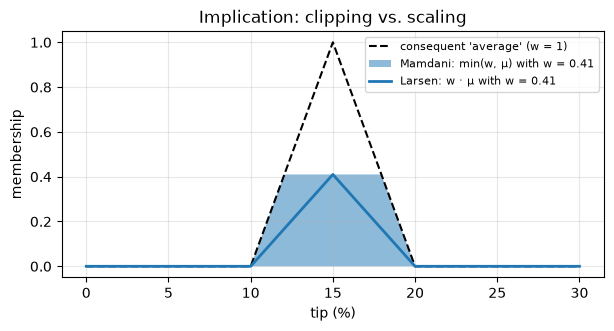

In [6]:
z = np.linspace(0, 30, 3001)                                          # output universe (tip in %)
avg = trimf(z, 10, 15, 20)                                            # consequent "tip is average"
w = 0.41                                                              # firing strength of the rule
plt.figure(figsize=(7, 3.2))
plt.plot(z, avg, "k--", label="consequent 'average' (w = 1)")
plt.fill_between(z, np.minimum(w, avg), alpha=0.5, label=f"Mamdani: min(w, μ) with w = {w}")
plt.plot(z, w * avg, lw=2, label=f"Larsen: w · μ with w = {w}")
plt.xlabel("tip (%)"); plt.ylabel("membership"); plt.title("Implication: clipping vs. scaling"); plt.legend(fontsize=8)
plt.grid(alpha=0.3); plt.show()

**What just happened?** With a firing strength of 0.41 the Mamdani rule produces a trapezoid (the triangle with its top
cut off at 0.41), while Larsen keeps the triangle shape but shrinks it to height 0.41. Both mean "the output is
*somewhat* average".

## 6. Mamdani inference step by step: a tipping controller

> 💡 **In plain English:** measure the inputs, apply all rules a little or a lot, combine them, and turn the result into one number.

**Problem** (the classic textbook and MATLAB example). Decide a restaurant tip between 0% and 30% from two scores
between 0 and 10: `service` and `food` quality.

| Variable | Terms and membership functions |
|---|---|
| service (input, 0 to 10) | poor = Gauss(0, 1.5), good = Gauss(5, 1.5), excellent = Gauss(10, 1.5) |
| food (input, 0 to 10) | rancid = trapezoid(0, 0, 1, 3), delicious = trapezoid(7, 9, 10, 10) |
| tip (output, 0 to 30 %) | cheap = triangle(0, 5, 10), average = triangle(10, 15, 20), generous = triangle(20, 25, 30) |

**Rule base**
1. IF service is poor **OR** food is rancid THEN tip is cheap
2. IF service is good THEN tip is average
3. IF service is excellent **OR** food is delicious THEN tip is generous

**The four steps of Mamdani inference** (Mamdani and Assilian, 1975, originally to control a steam engine):

```
 crisp inputs ──> 1. FUZZIFY ──> 2. EVALUATE RULES ──> 3. AGGREGATE ──> 4. DEFUZZIFY ──> crisp output
 service=3,food=8   μ of each term   firing strength w,     max of all        centroid or
                                     clip consequents       clipped sets      mean of maximum
```

**By hand for service = 3, food = 8:**
1. Fuzzify: $\mu_{poor}(3) = e^{-9/4.5} = 0.135$, $\mu_{good}(3) = e^{-4/4.5} = 0.411$, $\mu_{excellent}(3) \approx 0$;
   $\mu_{rancid}(8) = 0$, $\mu_{delicious}(8) = (8-7)/(9-7) = 0.5$.
2. Rules (OR = max): $w_1 = \max(0.135, 0) = 0.135$, $w_2 = 0.411$, $w_3 = \max(0.000, 0.5) = 0.5$.
   Clip cheap at 0.135, average at 0.411, generous at 0.5.
3. Aggregate: take the pointwise **max** of the three clipped sets.
4. Defuzzify:
   - **Centroid** (centre of gravity): $z^* = \dfrac{\int z\,\mu(z)\,dz}{\int \mu(z)\,dz}$, computed numerically on a fine grid.
   - **Mean of maximum (MOM)**: the average of the $z$ values where $\mu$ reaches its highest value. Here the
     highest level is 0.5, reached on the flat top of the clipped "generous" set, $z \in [22.5, 27.5]$, so MOM = 25.

In [7]:
# ---- The knowledge base of the controller ----
SERVICE = {"poor": lambda s: gaussmf(s, 0, 1.5), "good": lambda s: gaussmf(s, 5, 1.5),
           "excellent": lambda s: gaussmf(s, 10, 1.5)}
FOOD = {"rancid": lambda f: trapmf(f, 0, 0, 1, 3), "delicious": lambda f: trapmf(f, 7, 9, 10, 10)}
Z = np.linspace(0, 30, 3001)                                          # output universe, 0.01 % resolution
TIP = {"cheap": trimf(Z, 0, 5, 10), "average": trimf(Z, 10, 15, 20), "generous": trimf(Z, 20, 25, 30)}
# each rule: (list of (variable, term) antecedents, connective, consequent term)
RULES = [([("service", "poor"), ("food", "rancid")], "OR", "cheap"),
         ([("service", "good")], "AND", "average"),
         ([("service", "excellent"), ("food", "delicious")], "OR", "generous")]
INPUT_TERMS = {"service": SERVICE, "food": FOOD}

def fuzzify(inputs):
    # step 1: membership degree of every input value in every term
    return {(var, term): float(f(inputs[var])) for var, terms in INPUT_TERMS.items() for term, f in terms.items()}

def evaluate_rules(memberships, and_op=min, or_op=max):
    # step 2: firing strength of each rule (fuzzy AND/OR of its antecedents)
    strengths = []
    for antecedents, conn, consequent in RULES:
        degrees = [memberships[a] for a in antecedents]
        op = and_op if conn == "AND" else or_op
        w = degrees[0]
        for d in degrees[1:]:
            w = op(w, d)
        strengths.append((consequent, w))
    return strengths

def aggregate(strengths, implication="min"):
    # step 3: clip (or scale) each consequent by its firing strength, then combine with pointwise max
    out = np.zeros_like(Z)
    for consequent, w in strengths:
        shaped = np.minimum(w, TIP[consequent]) if implication == "min" else w * TIP[consequent]
        out = np.maximum(out, shaped)
    return out

def centroid(z, mu):
    # step 4a: centre of gravity (numerical integration with the trapezoidal rule)
    area = np.trapezoid(mu, z)
    return float(np.trapezoid(z * mu, z) / area) if area > 0 else float("nan")

def mean_of_max(z, mu, tol=1e-9):
    # step 4b: average of the z values where mu is (numerically) maximal
    return float(z[mu >= mu.max() - tol].mean())

def mamdani(service, food, defuzz="centroid", implication="min"):
    mu = aggregate(evaluate_rules(fuzzify({"service": service, "food": food})), implication)
    return centroid(Z, mu) if defuzz == "centroid" else mean_of_max(Z, mu)

# ---- Step-by-step trace for service = 3, food = 8 ----
inputs = {"service": 3.0, "food": 8.0}
m = fuzzify(inputs)
print("1. fuzzify:", {f"{v}.{t}": round(d, 3) for (v, t), d in m.items()})
st = evaluate_rules(m)
print("2. rule strengths:", [(c, round(w, 3)) for c, w in st])
agg = aggregate(st)
c_star, mom = centroid(Z, agg), mean_of_max(Z, agg)
print(f"4. centroid = {c_star:.2f} %   mean of maximum = {mom:.2f} %")
assert abs(m[("service", "good")] - math.exp(-4 / 4.5)) < 1e-12 and abs(m[("food", "delicious")] - 0.5) < 1e-12
assert abs(mom - 25.0) < 1e-6 and 0 <= c_star <= 30
# the centroid does not depend on the grid resolution (checked with a 10x finer grid)
Z_fine = np.linspace(0, 30, 30001)
agg_fine = np.zeros_like(Z_fine)
for c, w in st:
    base = {"cheap": (0, 5, 10), "average": (10, 15, 20), "generous": (20, 25, 30)}[c]
    agg_fine = np.maximum(agg_fine, np.minimum(w, trimf(Z_fine, *base)))
assert abs(centroid(Z_fine, agg_fine) - c_star) < 1e-3
# sanity check of the centroid code: a symmetric triangle has its centroid at the peak
assert abs(centroid(Z, TIP["average"]) - 15.0) < 1e-9

1. fuzzify: {'service.poor': 0.135, 'service.good': 0.411, 'service.excellent': 0.0, 'food.rancid': 0.0, 'food.delicious': 0.5}
2. rule strengths: [('cheap', 0.135), ('average', 0.411), ('generous', 0.5)]
4. centroid = 18.01 %   mean of maximum = 25.00 %


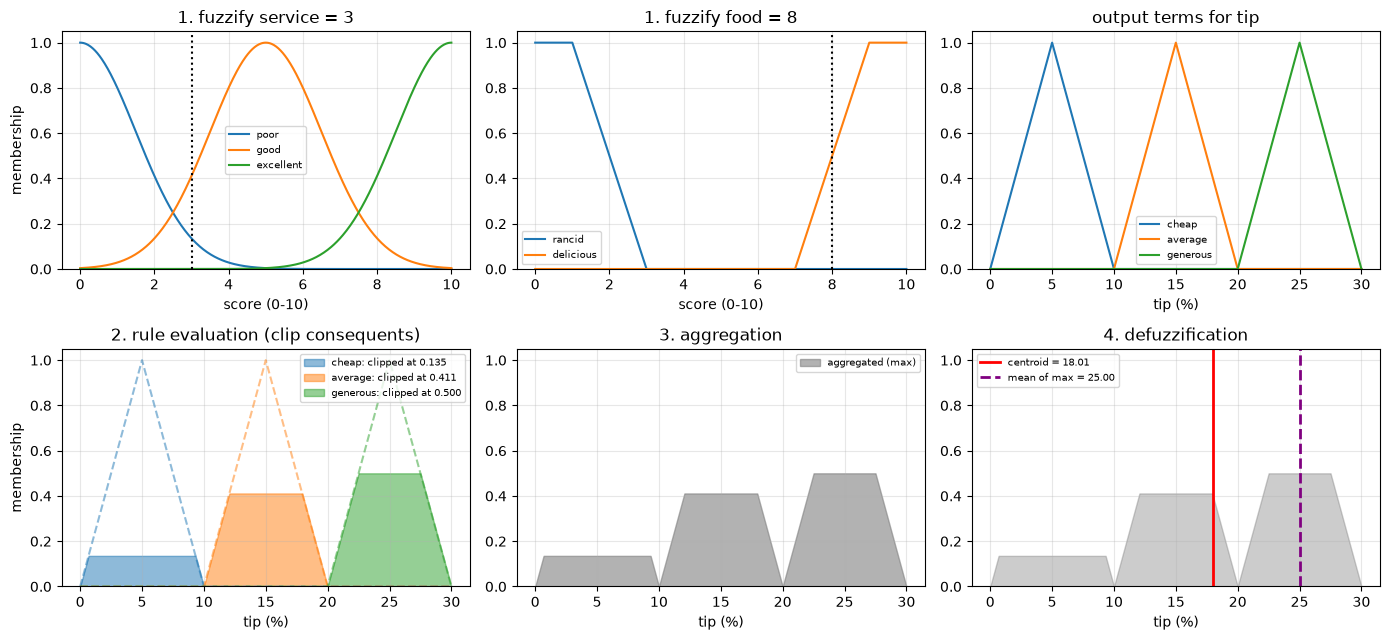

In [8]:
# Visualise the four steps
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
s_axis, f_axis = np.linspace(0, 10, 501), np.linspace(0, 10, 501)
for term, f in SERVICE.items():
    axes[0, 0].plot(s_axis, f(s_axis), label=term)
axes[0, 0].axvline(inputs["service"], color="k", ls=":"); axes[0, 0].set_title("1. fuzzify service = 3")
for term, f in FOOD.items():
    axes[0, 1].plot(f_axis, f(f_axis), label=term)
axes[0, 1].axvline(inputs["food"], color="k", ls=":"); axes[0, 1].set_title("1. fuzzify food = 8")
for term, mf in TIP.items():
    axes[0, 2].plot(Z, mf, label=term)
axes[0, 2].set_title("output terms for tip")
colors = {"cheap": "tab:blue", "average": "tab:orange", "generous": "tab:green"}
for c, w in st:
    axes[1, 0].plot(Z, TIP[c], "--", color=colors[c], alpha=0.5)
    axes[1, 0].fill_between(Z, np.minimum(w, TIP[c]), color=colors[c], alpha=0.5, label=f"{c}: clipped at {w:.3f}")
axes[1, 0].set_title("2. rule evaluation (clip consequents)")
axes[1, 1].fill_between(Z, agg, color="grey", alpha=0.6, label="aggregated (max)")
axes[1, 1].set_title("3. aggregation")
axes[1, 2].fill_between(Z, agg, color="grey", alpha=0.4)
axes[1, 2].axvline(c_star, color="red", lw=2, label=f"centroid = {c_star:.2f}")
axes[1, 2].axvline(mom, color="purple", lw=2, ls="--", label=f"mean of max = {mom:.2f}")
axes[1, 2].set_title("4. defuzzification")
for ax in axes.ravel():
    ax.legend(fontsize=7); ax.grid(alpha=0.3); ax.set_ylim(0, 1.05)
for ax in axes[0, :2]:
    ax.set_xlabel("score (0-10)")
for ax in list(axes[1]) + [axes[0, 2]]:
    ax.set_xlabel("tip (%)")
for ax in axes[:, 0]:
    ax.set_ylabel("membership")
plt.tight_layout(); plt.show()

**What just happened?** Service 3 is mostly "good" (0.411) and a little "poor" (0.135); food 8 is "delicious" to degree
0.5. So rule 3 (generous) fires most strongly, rule 2 (average) a bit less, rule 1 (cheap) weakly. The aggregated shape
has mass in all three regions, and its **centroid** is about **18.0%** (the same value on a 10 times finer grid). The
**mean of maximum** ignores everything except the highest plateau and answers 25%: it is "jumpier" because it only looks
at the winning rule.

| Defuzzifier | Idea | Pros | Cons |
|---|---|---|---|
| **Centroid (COG)** | balance point of the area | smooth output, uses every rule | needs an integral (slower) |
| **Bisector** | splits the area into two equal halves | similar to centroid | also needs integration |
| **Mean / smallest / largest of maximum** | look only at the peak plateau | very fast | output jumps when the winning rule changes |

**Complexity.** For $r$ rules with at most $k$ antecedents and an output grid of $G$ points: rule evaluation is
$O(rk)$, aggregation and centroid $O(rG)$.

## 7. The control surface, and Sugeno inference

> 💡 **In plain English:** draw the controller's answer for every input to check it behaves sensibly, and meet a faster variant.

A fuzzy controller is just a smooth function from inputs to output. Plotting the output for every input combination
(the **control surface**) is how engineers check that the rules behave sensibly: no holes, no unexpected jumps.

**Sugeno (Takagi-Sugeno-Kang, 1985) inference** keeps steps 1 and 2 but makes each rule's consequent a **function**
of the inputs instead of a fuzzy set, e.g. `THEN tip = 5` (zero order) or `THEN tip = 2 + 1.2·food` (first order). The
output is the weighted average $z^* = \sum_i w_i z_i / \sum_i w_i$. No aggregation or integration is needed, so it is
faster, differentiable (good for learning the parameters from data, as in ANFIS) and easy to analyse; Mamdani is more
intuitive for experts because outputs are also words.

Mamdani (centroid): min 5.08 %, max 24.92 %, 1236 ms for 961 points
Sugeno (order 0):   min 5.04 %, max 24.96 %, 828 ms
largest |Mamdani - Sugeno| difference: 2.14 percentage points
tip(0, 0) = 5.08 %,  tip(5, 5) = 15.00 %,  tip(10, 10) = 24.92 %


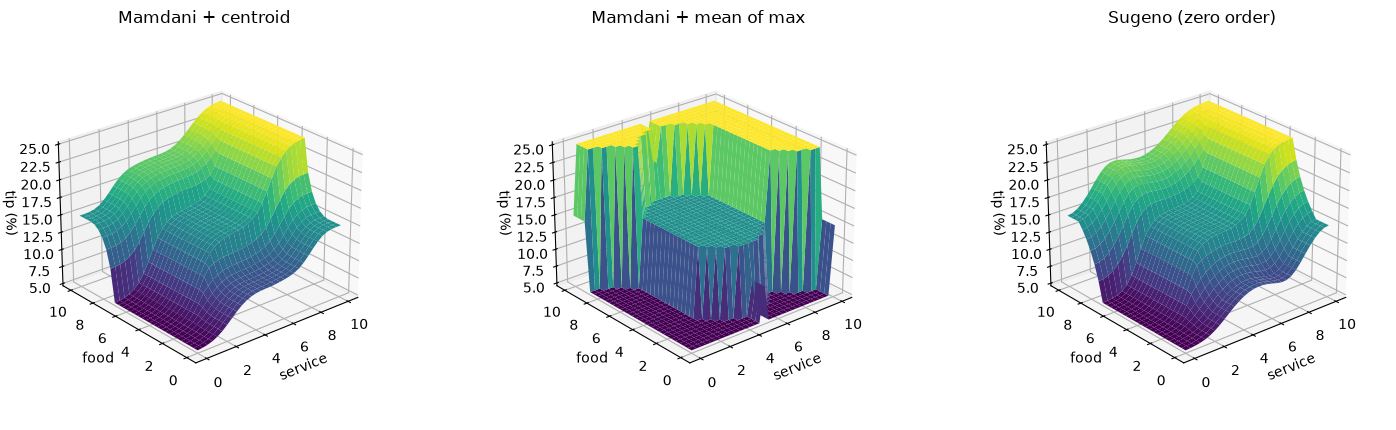

In [9]:
def sugeno(service, food, outputs={"cheap": 5.0, "average": 15.0, "generous": 25.0}):
    # zero-order Sugeno: each rule outputs a constant; final output = weighted average of the constants
    st = evaluate_rules(fuzzify({"service": service, "food": food}))
    num = sum(w * outputs[c] for c, w in st)
    den = sum(w for _, w in st)
    return num / den

grid = np.linspace(0, 10, 31)
S_, F_ = np.meshgrid(grid, grid, indexing="ij")
t0 = time.perf_counter()
surf_mamdani = np.array([[mamdani(s, f) for f in grid] for s in grid]); t_m = time.perf_counter() - t0
t0 = time.perf_counter()
surf_sugeno = np.array([[sugeno(s, f) for f in grid] for s in grid]); t_s = time.perf_counter() - t0
surf_mom = np.array([[mamdani(s, f, defuzz="mom") for f in grid] for s in grid])

print(f"Mamdani (centroid): min {surf_mamdani.min():.2f} %, max {surf_mamdani.max():.2f} %, {t_m * 1000:.0f} ms for {grid.size ** 2} points")
print(f"Sugeno (order 0):   min {surf_sugeno.min():.2f} %, max {surf_sugeno.max():.2f} %, {t_s * 1000:.0f} ms")
print(f"largest |Mamdani - Sugeno| difference: {np.abs(surf_mamdani - surf_sugeno).max():.2f} percentage points")
print(f"tip(0, 0) = {mamdani(0, 0):.2f} %,  tip(5, 5) = {mamdani(5, 5):.2f} %,  tip(10, 10) = {mamdani(10, 10):.2f} %")
assert surf_mamdani.min() >= 0 and surf_mamdani.max() <= 30 and mamdani(0, 0) < mamdani(5, 5) < mamdani(10, 10)
assert abs(sugeno(5, 5) - 15.0) < 0.05                                # only rule 2 fires (almost) at the centre

fig = plt.figure(figsize=(15, 4.4))
for i, (title, surf) in enumerate([("Mamdani + centroid", surf_mamdani), ("Mamdani + mean of max", surf_mom),
                                   ("Sugeno (zero order)", surf_sugeno)]):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")
    ax.plot_surface(S_, F_, surf, cmap="viridis", edgecolor="none")
    ax.set_xlabel("service"); ax.set_ylabel("food"); ax.set_zlabel("tip (%)"); ax.set_title(title)
    ax.view_init(elev=25, azim=-130); ax.set_box_aspect(None, zoom=0.85)   # zoom out so labels fit
plt.tight_layout(); plt.show()

**What just happened?** The centroid surface is smooth and rises with both service and food (about 5% for terrible
service and food, 15% for average, 25% for excellent). The mean-of-maximum surface has **plateaus and jumps**, which is
why centroid is preferred for control. The Sugeno surface has the same overall shape (constants 5, 15, 25 are the peaks of
the Mamdani output sets) but is computed faster because it needs no integration over the output axis (in our
Python code much of the time is shared overhead, such as fuzzification, so the measured gap is modest).

> ⚠️ **Common mistake.** Forgetting that a rule base must *cover* the input space. If for some inputs no rule fires
> ($\sum w_i = 0$), the centroid is undefined (0/0). Here the Gaussian service terms overlap everywhere, so at least one
> rule always fires; with triangles that do not overlap you would get holes.

---
# Part 2: Rule-based expert systems

## 8. Architecture of a rule-based expert system

> 💡 **In plain English:** rules, facts, an engine that applies the rules, and a part that explains the answer.

**Intuition.** An **expert system** captures the know-how of a human specialist as many small IF-THEN rules ("IF the
engine does not crank AND the lights are dim THEN the battery is probably weak"), and a general-purpose program applies
them to the facts of a new case, like a junior employee following the specialist's checklist.

```
                 ┌──────────────────────────┐
 user  <──────>  │      user interface      │
                 └────────────┬─────────────┘
                              │ questions / answers / explanations
 ┌──────────────────┐   ┌─────▼──────────────┐   ┌──────────────────────────┐
 │  KNOWLEDGE BASE  │──>│  INFERENCE ENGINE  │<─>│  WORKING MEMORY (facts)  │
 │  IF-THEN rules   │   │ match-resolve-act  │   │ case data + conclusions  │
 └────────▲─────────┘   └─────┬──────────────┘   └──────────────────────────┘
          │                   │
 knowledge acquisition   EXPLANATION FACILITY ("why are you asking?", "how did you conclude that?")
 (knowledge engineer + domain expert)
```

| Component | Role |
|---|---|
| **Knowledge base** | long-term domain knowledge: the rules (production rules) |
| **Working memory** | short-term facts about the current case, including intermediate conclusions |
| **Inference engine** | decides which rule to apply next: **match** rules against facts, **resolve** conflicts, **act** (fire one rule) |
| **Explanation facility** | answers **why** a question is asked and **how** a conclusion was reached; essential for trust |
| **Knowledge acquisition** | the (slow, expensive) process of getting rules from experts; the famous *knowledge acquisition bottleneck* |

The key idea is the separation of **knowledge** (rules, editable by experts) from **control** (the engine, generic).

**History in one table:**

| System | Year | Domain |
|---|---|---|
| DENDRAL (Stanford) | 1965 onwards | identifying molecules from mass spectra |
| MYCIN (Stanford) | 1970s | diagnosing blood infections, recommending antibiotics; introduced certainty factors |
| R1 / XCON (CMU and DEC) | 1980 | configuring VAX computer orders; widely reported to save DEC tens of millions of dollars per year |
| OPS5 (CMU), CLIPS (NASA) | 1980s | general production-rule languages; CLIPS (1985) is still maintained |
| Drools and other business rules engines | 2000s to today | insurance, banking, compliance, pricing |

## 9. Forward chaining with conflict resolution

> 💡 **In plain English:** start from the facts, keep firing rules that apply, and decide which rule goes first when several do.

**Forward chaining** (data-driven) starts from the known facts and repeatedly fires rules whose conditions are satisfied,
adding their conclusions to working memory, until nothing new can be added (a **fixed point**) or a rule says stop. Each
cycle has three steps:

1. **Match**: find all rule instances whose conditions are true in working memory. This set is the **conflict set** (or
   *agenda*).
2. **Resolve**: choose one activation with a **conflict resolution strategy**.
3. **Act**: fire it (add facts, print advice, or halt).

**Conflict resolution strategies** (as in OPS5 / CLIPS):

| Strategy | Rule chosen | Why |
|---|---|---|
| **Refraction** | never fire the same rule on the same facts twice | prevents infinite loops (always on) |
| **Salience / priority** | highest priority first | safety rules must win |
| **Specificity** | the rule with more conditions first | a specific rule is an exception to a general one |
| **Recency** | the rule matching the most recently added facts | follows the current line of reasoning |
| **Rule order** | first rule in the file | simple, but fragile |

Our small knowledge base diagnoses **why a car will not start**. A condition `"not x"` means "x is not in working
memory" (**negation as failure**, a closed-world assumption). Diagnosis rules only use positive conditions, so their
result does not depend on the order of firing; only the **advice** rules compete, which is where conflict resolution
matters.

In [10]:
class Rule:
    def __init__(self, name, conditions, conclusion, salience=0, text=""):
        self.name, self.conditions, self.conclusion = name, list(conditions), conclusion
        self.salience, self.text = salience, text
    @property
    def specificity(self):
        return len(self.conditions)                                       # more conditions = more specific
    def __repr__(self):
        return f"{self.name}: IF {' AND '.join(self.conditions)} THEN {self.conclusion}"

KB = [
    # safety rule: highest salience, stops the session
    Rule("R0", ["fuel_smell"], "STOP: possible fuel leak, do not try to start, call a mechanic", salience=100,
         text="a fuel smell means a fire risk"),
    # diagnosis rules (positive conditions only)
    Rule("R1", ["engine_does_not_crank", "lights_dim"], "battery_weak", text="no crank + dim lights = weak battery"),
    Rule("R2", ["engine_does_not_crank", "clicking_sound"], "battery_weak", text="rapid clicking = weak battery"),
    Rule("R3", ["engine_does_not_crank", "lights_bright", "single_click"], "starter_motor_fault",
         text="good battery but the starter does not turn"),
    Rule("R4", ["engine_cranks", "fuel_gauge_empty"], "out_of_fuel", text="cranks but no fuel"),
    Rule("R5", ["engine_cranks", "fuel_gauge_ok", "no_spark"], "ignition_fault", text="fuel present but no spark"),
    Rule("R6", ["engine_cranks", "fuel_gauge_ok", "spark_ok"], "fuel_delivery_fault", text="spark present: suspect fuel pump/filter"),
    Rule("R7", ["battery_weak", "battery_older_than_5_years"], "battery_end_of_life", text="old battery that is weak"),
    # advice rules: they compete; each one blocks the others by asserting advice_given
    Rule("A1", ["battery_weak", "not advice_given"], "ADVICE: jump-start the car, then charge the battery"),
    Rule("A2", ["battery_end_of_life", "battery_weak", "not advice_given"], "ADVICE: replace the battery (it is old)"),
    Rule("A3", ["starter_motor_fault", "not advice_given"], "ADVICE: tap the starter or have it replaced"),
    Rule("A4", ["out_of_fuel", "not advice_given"], "ADVICE: add fuel"),
    Rule("A5", ["ignition_fault", "not advice_given"], "ADVICE: check spark plugs and ignition coil"),
    Rule("A6", ["fuel_delivery_fault", "not advice_given"], "ADVICE: check fuel pump fuse and fuel filter"),
]

def holds(cond, wm):
    # a condition is either a fact name or "not <fact>" (negation as failure)
    return cond[4:] not in wm if cond.startswith("not ") else cond in wm

class ForwardChainer:
    def __init__(self, kb, strategy=("salience", "specificity", "recency")):
        self.kb, self.strategy = kb, strategy

    def run(self, initial_facts, verbose=True):
        self.wm = {f: i for i, f in enumerate(initial_facts)}              # fact -> timestamp (for recency)
        self.why = {f: ("given", []) for f in initial_facts}               # justification of every fact
        self.fired, self.trace, self.output, clock = set(), [], [], len(initial_facts)
        while True:
            # 1. MATCH: all activations not fired before (refraction)
            conflict_set = [r for r in self.kb if r.name not in self.fired and all(holds(c, self.wm) for c in r.conditions)]
            conflict_set = [r for r in conflict_set if r.conclusion not in self.wm]   # would add nothing new
            if not conflict_set:
                break
            # 2. RESOLVE: sort by the chosen strategy keys (all "higher is better")
            def key(r):
                k = {"salience": r.salience, "specificity": r.specificity,
                     "recency": max([self.wm.get(c, -1) for c in r.conditions if not c.startswith("not ")] or [-1]),
                     "rule_order": -self.kb.index(r)}
                return tuple(k[s] for s in self.strategy)
            conflict_set.sort(key=key, reverse=True)
            rule = conflict_set[0]
            # 3. ACT
            self.fired.add(rule.name)
            self.trace.append({"cycle": len(self.trace) + 1, "conflict set": [r.name for r in conflict_set],
                               "fired": rule.name, "adds": rule.conclusion})
            premises = [c for c in rule.conditions if not c.startswith("not ")]
            if rule.conclusion.startswith("STOP"):
                self.output.append(rule.conclusion); self.why[rule.conclusion] = (rule.name, premises)
                break                                                       # halt the session
            if rule.conclusion.startswith("ADVICE"):
                self.output.append(rule.conclusion)
                self.wm["advice_given"] = clock; clock += 1
                self.why["advice_given"] = (rule.name, premises)
            self.wm[rule.conclusion] = clock; clock += 1
            self.why[rule.conclusion] = (rule.name, premises)
        if verbose:
            display(pd.DataFrame(self.trace).set_index("cycle"))
        return self.output

case_1 = ["engine_does_not_crank", "lights_dim", "clicking_sound", "battery_older_than_5_years"]
print("CASE 1 facts:", case_1)
engine = ForwardChainer(KB)
print("result:", engine.run(case_1))

CASE 1 facts: ['engine_does_not_crank', 'lights_dim', 'clicking_sound', 'battery_older_than_5_years']


,conflict set,fired,adds
cycle,,,
1,"[R2, R1]",R2,battery_weak
2,"[R7, A1]",R7,battery_end_of_life
3,"[A2, A1]",A2,ADVICE: replace the battery (it is old)


result: ['ADVICE: replace the battery (it is old)']


**What just happened?** In cycle 1 both R1 and R2 match (two independent reasons for `battery_weak`). They have the same
salience and the same specificity (2 conditions), so **recency** decides: `clicking_sound` (entered third) is newer than
`lights_dim` (entered second), so R2 fires. After that, R1 would add nothing new and leaves the agenda. R7 concludes `battery_end_of_life`. Now **two advice rules compete**: the general A1 (2 conditions)
and the specific A2 (3 conditions). **Specificity** picks A2, which asserts `advice_given` and blocks A1. The engine stops
at a fixed point: no rule can add anything new.

Let us see what changes with a different strategy and with the safety rule.

In [11]:
# Same case, but conflict resolution = rule order only (first rule in the file wins)
naive_engine = ForwardChainer(KB, strategy=("rule_order",))
print("rule-order strategy  ->", naive_engine.run(case_1, verbose=False))
print("specificity strategy ->", ForwardChainer(KB).run(case_1, verbose=False))

# Safety: salience makes the STOP rule win even though other rules also match
case_2 = ["engine_cranks", "fuel_gauge_ok", "no_spark", "fuel_smell"]
print("\nCASE 2 facts:", case_2)
print("salience strategy    ->", ForwardChainer(KB).run(case_2, verbose=False))
print("rule-order strategy  ->", ForwardChainer(KB, strategy=("rule_order",)).run(case_2, verbose=False))
reversed_kb = list(reversed(KB))                                  # the same rules, written in the opposite order
print("rule order, rules reversed ->", ForwardChainer(reversed_kb, strategy=("rule_order",)).run(case_2, verbose=False))

rule-order strategy  -> ['ADVICE: jump-start the car, then charge the battery']
specificity strategy -> ['ADVICE: replace the battery (it is old)']

CASE 2 facts: ['engine_cranks', 'fuel_gauge_ok', 'no_spark', 'fuel_smell']
salience strategy    -> ['STOP: possible fuel leak, do not try to start, call a mechanic']
rule-order strategy  -> ['STOP: possible fuel leak, do not try to start, call a mechanic']
rule order, rules reversed -> ['ADVICE: check spark plugs and ignition coil', 'STOP: possible fuel leak, do not try to start, call a mechanic']


**What just happened?**
- With **rule order** as the only strategy, the general advice A1 ("jump-start") fires before A2 because it is written
  first, and the important advice "replace the old battery" is lost. Specificity fixes this without depending on where
  a rule happens to be written.
- In case 2 the safety rule R0 fires first under **salience**, and the session stops. With rule order it also happens to
  win (R0 is the first rule), but as soon as someone edits the file and the order changes, the engine goes on to give
  ignition advice to a car that is leaking fuel. **Never rely on rule order for safety**; use explicit priorities.

**Complexity.** Our naive matcher tests every rule against working memory in every cycle: $O(R \cdot C)$ per cycle for
$R$ rules with up to $C$ conditions (set lookups are $O(1)$), and at most $R$ cycles here. Real engines with
thousands of rules and facts use the **Rete algorithm** (Forgy, 1979/1982), which stores partial matches in a network so
that each cycle only processes the *changes* in working memory. Drools uses a Rete-derived algorithm (PHREAK).

## 10. Explanations: "how" and "why"

> 💡 **In plain English:** the system can show how it reached a conclusion and why it is asking a question.

Experts trust a system only if it can justify itself. Two classic questions:
- **HOW did you conclude X?** Show the chain of rules and facts that led to X (a proof tree). Our forward chainer
  records, for every fact, which rule produced it and from which premises.
- **WHY are you asking me this?** This arises in **backward chaining** (goal-driven reasoning, as in MYCIN): the system
  starts from a hypothesis (goal), looks for rules that conclude it, and asks the user only for facts it really needs.
  "Why" is answered by showing the current goal stack: *"I am asking about the lights because rule R1 would conclude
  `battery_weak` if they are dim, and `battery_weak` is needed by rule R7 to prove `battery_end_of_life`."*

| | Forward chaining | Backward chaining |
|---|---|---|
| Direction | facts → conclusions (data-driven) | goal → needed facts (goal-driven) |
| Good when | many facts arrive, many possible conclusions (monitoring, configuration) | few hypotheses to check, facts are costly to obtain (diagnosis by questions) |
| Asks questions? | no, uses the data it has | yes, only relevant ones |
| Classic systems | OPS5, XCON, CLIPS, Drools | MYCIN, Prolog |

In [12]:
def how(fact, why_table, indent=0):
    # print the proof tree of a fact using the recorded justifications
    source, premises = why_table.get(fact, ("unknown", []))
    pad = "    " * indent
    if source == "given":
        print(f"{pad}- {fact}: given by the user")
        return
    rule = next(r for r in KB if r.name == source)
    print(f"{pad}- {fact}: concluded by rule {source} ({rule.text or rule.conclusion}) from:")
    for p in premises:
        how(p, why_table, indent + 1)

engine = ForwardChainer(KB); engine.run(case_1, verbose=False)
print("HOW did you conclude that the battery should be replaced?")
how("advice_given", engine.why)

HOW did you conclude that the battery should be replaced?
- advice_given: concluded by rule A2 (ADVICE: replace the battery (it is old)) from:
    - battery_end_of_life: concluded by rule R7 (old battery that is weak) from:
        - battery_weak: concluded by rule R2 (rapid clicking = weak battery) from:
            - engine_does_not_crank: given by the user
            - clicking_sound: given by the user
        - battery_older_than_5_years: given by the user
    - battery_weak: concluded by rule R2 (rapid clicking = weak battery) from:
        - engine_does_not_crank: given by the user
        - clicking_sound: given by the user


In [13]:
class BackwardChainer:
    # goal-driven consultation; 'answers' is a scripted user (no input() so the notebook runs headless)
    ASKABLE = {
        "engine_does_not_crank": "Does the engine fail to turn over when you turn the key?",
        "engine_cranks": "Does the engine turn over (crank)?",
        "lights_dim": "Are the dashboard lights dim?", "lights_bright": "Are the dashboard lights bright?",
        "clicking_sound": "Do you hear rapid clicking?", "single_click": "Do you hear a single click?",
        "fuel_gauge_empty": "Is the fuel gauge on empty?", "fuel_gauge_ok": "Does the fuel gauge show fuel?",
        "no_spark": "Is there no spark at the plugs?", "spark_ok": "Is there a spark at the plugs?",
        "battery_older_than_5_years": "Is the battery older than 5 years?", "fuel_smell": "Do you smell fuel?",
    }
    def __init__(self, kb, answers, verbose=True):
        self.kb, self.answers, self.verbose = kb, answers, verbose
        self.known, self.transcript = {}, []

    COMPLEMENT = {"engine_cranks": "engine_does_not_crank", "fuel_gauge_empty": "fuel_gauge_ok", "no_spark": "spark_ok"}
    COMPLEMENT.update({v: k for k, v in list(COMPLEMENT.items())})            # make the pairs symmetric

    def ask(self, fact, stack):
        other = self.COMPLEMENT.get(fact)
        if fact not in self.known and other in self.known:                       # answer implied by an earlier one
            self.known[fact] = not self.known[other]
        if fact not in self.known:
            answer = self.answers.get(fact, False)                             # scripted user: unknown -> "no"
            self.known[fact] = answer
            why = " <- ".join(f"{g} (needed by {r})" for g, r in reversed(stack)) or "top-level goal"
            self.transcript.append({"question": self.ASKABLE[fact], "answer": "yes" if answer else "no",
                                    "WHY are you asking?": f"to establish {why}"})
        return self.known[fact]

    def prove(self, goal, stack=()):
        if goal in self.ASKABLE:
            return self.ask(goal, stack)
        if goal in self.known:
            return self.known[goal]
        for rule in self.kb:                                                    # rules that conclude the goal
            if rule.conclusion == goal:
                if all(self.prove(c, stack + ((goal, rule.name),)) for c in rule.conditions):
                    self.known[goal] = True
                    return True
        self.known[goal] = False
        return False

    def diagnose(self, hypotheses):
        found = [h for h in hypotheses if self.prove(h)]
        if self.verbose:
            display(pd.DataFrame(self.transcript))
        return found

DIAGNOSES = ["battery_end_of_life", "battery_weak", "starter_motor_fault", "out_of_fuel", "ignition_fault",
             "fuel_delivery_fault"]
user = {"engine_does_not_crank": True, "lights_dim": True, "battery_older_than_5_years": True}
bc = BackwardChainer([r for r in KB if not r.conclusion.startswith(("ADVICE", "STOP"))], user)
print("diagnoses proven:", bc.diagnose(DIAGNOSES))
print(f"questions asked: {len(bc.transcript)} of {len(BackwardChainer.ASKABLE)} possible")

,question,answer,WHY are you asking?
0,Does the engine fail to turn over when you turn the key?,yes,to establish battery_weak (needed by R1) <- battery_end_of_life (needed by R7)
1,Are the dashboard lights dim?,yes,to establish battery_weak (needed by R1) <- battery_end_of_life (needed by R7)
2,Is the battery older than 5 years?,yes,to establish battery_end_of_life (needed by R7)
3,Are the dashboard lights bright?,no,to establish starter_motor_fault (needed by R3)


diagnoses proven: ['battery_end_of_life', 'battery_weak']
questions asked: 4 of 12 possible


In [14]:
# Verification: backward chaining proves exactly the diagnoses that forward chaining derives, for EVERY consistent
# combination of answers (3 complementary yes/no pairs + 6 independent questions = 2^9 = 512 cases),
# and forward chaining always ends at a fixed point.
diag_rules = [r for r in KB if not r.conclusion.startswith(("ADVICE", "STOP"))]
pairs = [("engine_cranks", "engine_does_not_crank"), ("fuel_gauge_empty", "fuel_gauge_ok"), ("no_spark", "spark_ok")]
singles = [a for a in BackwardChainer.ASKABLE if not any(a in p for p in pairs)]
mismatch, n_cases = 0, 0
for values in itertools.product([False, True], repeat=len(pairs) + len(singles)):
    answers = {}
    for (yes, no), v in zip(pairs, values[:len(pairs)]):
        answers[yes], answers[no] = v, not v                                   # exactly one of each pair is true
    answers.update(zip(singles, values[len(pairs):]))
    facts = [a for a, v in answers.items() if v]
    n_cases += 1
    fc = ForwardChainer(diag_rules); fc.run(facts, verbose=False)
    fwd = {d for d in DIAGNOSES if d in fc.wm}
    for r in diag_rules:                                                        # fixed point: nothing left to add
        assert not (all(holds(c, fc.wm) for c in r.conditions) and r.conclusion not in fc.wm)
    bwd = set(BackwardChainer(diag_rules, answers, verbose=False).diagnose(DIAGNOSES))
    mismatch += fwd != bwd
assert mismatch == 0 and n_cases == 512
print(f"forward and backward chaining agree on all {n_cases} consistent cases")

forward and backward chaining agree on all 512 consistent cases


**What just happened?**
- The **HOW** explanation prints a proof tree: the advice came from rule A2, which needed `battery_end_of_life` (from
  R7) and `battery_weak` (from R2, from two facts the user gave).
- The **backward chainer** asked only the questions it needed, in goal order, and for each one recorded **WHY** it was
  asking, as a chain of goals and rules. It never asked about the fuel gauge or sparks, because once the engine does not
  crank, the rules about cranking engines fail at their first condition. It also did not ask "does the engine crank?":
  that is the complement of an answer it already has. It never asked about clicking either: `battery_weak` was already
  proven by R1, so R2 was not needed. It did ask whether the lights are bright, to test the starter-motor hypothesis.
- Over all 512 consistent combinations of answers (the three yes/no pairs such as cranks / does not crank are never both
  true), forward and backward chaining derive exactly the same diagnoses, and forward chaining always stops at a true
  fixed point.

**Complexity.** Backward chaining explores an AND-OR tree of rules; without caching it can repeat work exponentially,
which is why we cache known facts (`self.known`). With caching each fact is proven at most once: $O(R \cdot C)$ here.

The function below lets *you* be the user (it is not run here because notebooks are executed automatically):

In [15]:
def consult():
    # Interactive version: answer y/n; type 'why' to see why a question is asked. Call consult() yourself to try it.
    class Interactive(BackwardChainer):
        def ask(self, fact, stack):
            if fact not in self.known:
                while True:
                    reply = input(self.ASKABLE[fact] + " (y/n/why) ").strip().lower()
                    if reply == "why":
                        print("  I am trying to establish:", " <- ".join(f"{g} (rule {r})" for g, r in reversed(stack)))
                        continue
                    self.known[fact] = reply.startswith("y"); break
            return self.known[fact]
    found = Interactive(diag_rules, {}, verbose=False).diagnose(DIAGNOSES)
    print("Diagnoses:", found or "none of the known faults")
# consult()   # <- uncomment to run interactively

## 11. Certainty factors (MYCIN, historical)

> 💡 **In plain English:** an old shortcut for "how sure" that was simple but not quite consistent.

Real rules are not certain ("dim lights *suggest* a weak battery"). MYCIN attached a **certainty factor** $CF \in [-1, 1]$
to rules and facts: +1 = definitely true, -1 = definitely false, 0 = unknown. The (EMYCIN) calculus:

| Situation | Formula |
|---|---|
| premise with AND | $CF = \min(CF_1, CF_2, \dots)$ |
| premise with OR | $CF = \max(CF_1, CF_2, \dots)$ |
| applying a rule | $CF(\text{conclusion}) = CF(\text{rule}) \times CF(\text{premise})$, only if $CF(\text{premise}) > 0.2$ |
| two rules, both $\ge 0$ | $CF = CF_1 + CF_2 (1 - CF_1)$ |
| both $< 0$ | $CF = CF_1 + CF_2 (1 + CF_1)$ |
| mixed signs | $CF = \dfrac{CF_1 + CF_2}{1 - \min(\lvert CF_1 \rvert, \lvert CF_2 \rvert)}$ |

**By hand.** Two rules support `battery_weak` with 0.6 and 0.5: $0.6 + 0.5 \times 0.4 = 0.8$. Evidence for (0.6) and
against (-0.4): $(0.6 - 0.4)/(1 - 0.4) = 0.333$.

**Why it was abandoned.** CFs were designed to be cheap and modular, but Heckerman (1986) showed they correspond to a
consistent probabilistic model only under strong independence assumptions; with overlapping evidence they double-count.
Bayesian networks (previous notebook) replaced them. They are still a nice example of *approximate reasoning* and appear
in exam syllabi.

In [16]:
def cf_combine(a, b):
    # EMYCIN combination of two certainty factors for the same conclusion
    if a >= 0 and b >= 0:
        return a + b * (1 - a)
    if a < 0 and b < 0:
        return a + b * (1 + a)
    return (a + b) / (1 - min(abs(a), abs(b)))

assert abs(cf_combine(0.6, 0.5) - 0.8) < 1e-12 and abs(cf_combine(0.6, -0.4) - 1 / 3) < 1e-12
rng = random.Random(1)
for _ in range(20_000):                                                       # algebraic properties, tested
    x, y, w = (rng.uniform(-0.99, 0.99) for _ in range(3))
    assert abs(cf_combine(x, y) - cf_combine(y, x)) < 1e-12                   # commutative
    assert abs(cf_combine(cf_combine(x, y), w) - cf_combine(x, cf_combine(y, w))) < 1e-9   # order of evidence irrelevant
    assert -1 <= cf_combine(x, y) <= 1                                        # stays in range

CF_RULES = [  # (name, premise facts (AND), conclusion, rule CF)
    ("R1", ["engine_does_not_crank", "lights_dim"], "battery_weak", 0.8),
    ("R2", ["engine_does_not_crank", "clicking_sound"], "battery_weak", 0.6),
    ("R3", ["engine_does_not_crank", "lights_bright", "single_click"], "starter_motor_fault", 0.7),
    ("R3b", ["lights_bright"], "battery_weak", -0.5),                          # evidence AGAINST a weak battery
    ("R7", ["battery_weak", "battery_older_than_5_years"], "battery_end_of_life", 0.7),
]

def cf_infer(facts_cf, threshold=0.2):
    # propagate CFs through the rules until nothing changes (rules here form a DAG, so a few passes suffice)
    cf, log = dict(facts_cf), []
    for _ in range(len(CF_RULES)):
        derived = defaultdict(list)
        for name, prem, concl, rcf in CF_RULES:
            p = min(cf.get(f, 0.0) for f in prem)                                  # AND = min
            if p > threshold:                                                      # MYCIN's 0.2 threshold
                derived[concl].append((name, rcf * p))
        new = dict(facts_cf)
        for concl, contribs in derived.items():
            total = contribs[0][1]
            for _, c in contribs[1:]:
                total = cf_combine(total, c)
            new[concl] = total
        if new == cf:
            break
        cf = new
    for concl, contribs in derived.items():
        log.append({"conclusion": concl, "contributions": ", ".join(f"{n}: {c:+.3f}" for n, c in contribs),
                    "combined CF": cf[concl]})
    return cf, pd.DataFrame(log)

# The user is fairly sure the engine does not crank, thinks the lights are 'somewhat dim', heard some clicking,
# and is not sure about the battery age
user_cf = {"engine_does_not_crank": 0.9, "lights_dim": 0.6, "clicking_sound": 0.5, "battery_older_than_5_years": 0.4,
           "lights_bright": 0.3}
cf_result, cf_log = cf_infer(user_cf)
cf_log

,conclusion,contributions,combined CF
0,battery_weak,"R1: +0.480, R2: +0.300, R3b: -0.150",0.572
1,battery_end_of_life,R7: +0.280,0.280


**What just happened?** `battery_weak` gets three contributions: R1 gives $0.8 \times \min(0.9, 0.6) = 0.48$, R2 gives
$0.6 \times \min(0.9, 0.5) = 0.30$, and R3b gives evidence *against* it, $-0.5 \times 0.3 = -0.15$. Combining the
positive ones gives $0.48 + 0.30 \times 0.52 = 0.636$, and the negative one lowers it to $(0.636 - 0.15)/(1 - 0.15)
\approx 0.572$. `battery_end_of_life` then gets $0.7 \times \min(0.572, 0.4) = 0.28$. R3 does not fire because its premise
$\min(0.9, 0.3, 0) = 0$ is below the 0.2 threshold. The tests above confirm that the combination is commutative and that
the order in which evidence arrives does not matter.

> ⚠️ **Common mistake.** Reading a CF as a probability. A CF of 0.57 is a *change in belief* on an ad-hoc scale; two
> rules that use the same underlying evidence will both push it up (double counting), which a Bayesian network would
> not do.

## 12. Strengths, limits, and where these systems are used today

> 💡 **In plain English:** where rules and fuzzy control shine, where they fail, and where you find them today.

| | Fuzzy logic controllers | Rule-based expert systems |
|---|---|---|
| **Strengths** | encode expert know-how in words; smooth, robust control without a precise mathematical model; cheap to run on tiny chips | transparent and auditable (every decision has an explanation); easy to change one rule; no training data needed; deterministic |
| **Limits** | rules and membership functions are hand-tuned; the number of rules grows exponentially with inputs ($t^n$ for $t$ terms and $n$ inputs); no guarantee of stability without extra analysis | knowledge acquisition bottleneck; brittle outside the rules ("cliff" behaviour); rule interactions become hard to maintain at thousands of rules; poor at perception (images, text) and at learning from data |

**Where they are still used (2026):**
- **Fuzzy control**: consumer appliances (washing machines, rice cookers, air conditioners), camera autofocus and
  exposure, parts of automotive systems, and industrial process control. Famous early cases: the F.L. Smidth cement
  kiln controller in Denmark (around 1980) and the Sendai subway in Japan (opened 1987, Hitachi), whose fuzzy predictive
  train control gave smoother acceleration and braking and lower energy use. Today fuzzy controllers often sit next to
  PID controllers, or are tuned automatically (neuro-fuzzy systems such as ANFIS).
- **Business rules engines**: Drools (open source, part of the KIE / Apache KIE community), IBM Operational Decision
  Manager, FICO Blaze Advisor and similar tools run loan eligibility, insurance underwriting, pricing, fraud and
  compliance rules in banks, insurers and governments. Clinical decision support alerts in hospitals are also largely
  rule-based. The DMN (Decision Model and Notation) standard describes such decision tables.
- **Hybrid AI**: rules wrap machine-learning models as **guardrails** (e.g. "never approve a loan above X without a
  human", "block an LLM answer that contains a card number"), and LLM agents call deterministic rule engines as tools
  when an answer must be exact and auditable.

## 🔗 How this connects to modern AI
- **Neuro-fuzzy systems** (ANFIS, 1993) learn the parameters of a Sugeno system by gradient descent: a direct ancestor
  of differentiable rule learning.
- **Expert systems → knowledge graphs and agents.** The knowledge-base / inference-engine split lives on in knowledge
  graphs with reasoners ([`../../08_LLM/09_knowledge_graphs/01_knowledge_graphs.ipynb`](../../08_LLM/09_knowledge_graphs/01_knowledge_graphs.ipynb))
  and in LLM agents that combine a learned "brain" with deterministic tools and policies
  ([`../../10_Agents/01_agent_fundamentals.ipynb`](../../10_Agents/01_agent_fundamentals.ipynb)).
- **Explainability.** The "how" explanation of an expert system is what modern XAI tries to recover for black-box
  models ([`../../00_AI_Fundamentals/02_transparency_and_explainability.ipynb`](../02_transparency_and_explainability.ipynb)).
- **Uncertainty.** Certainty factors lost to Bayesian networks ([`09_uncertain_knowledge_and_reasoning.ipynb`](09_uncertain_knowledge_and_reasoning.ipynb)),
  which in turn led to today's probabilistic machine learning.

## Recap
- A **fuzzy set** has a membership function $\mu : X \to [0, 1]$; it models **vagueness**, not uncertainty.
- Common shapes: **triangular**, **trapezoidal**, **Gaussian**. A **linguistic variable** has overlapping terms;
  **hedges** reshape them (very = $\mu^2$, somewhat = $\sqrt{\mu}$).
- Fuzzy AND is any **t-norm** (min, product, Łukasiewicz, drastic), fuzzy OR its dual **t-conorm**, NOT is $1 - \mu$.
- **Mamdani inference**: fuzzify → evaluate rules (firing strengths, clip consequents) → aggregate (max) → defuzzify
  (centroid, mean of maximum). **Sugeno** uses functions as consequents and a weighted average.
- An **expert system** = knowledge base + working memory + inference engine + explanation facility.
- **Forward chaining** is data-driven (match-resolve-act); **conflict resolution** uses refraction, salience,
  specificity and recency. **Backward chaining** is goal-driven and supports "why" questions; "how" explanations replay
  the proof tree.
- **Certainty factors** were a historical, approximate alternative to probability, replaced by Bayesian networks.

## Practice problems

**1. (Easy)** Compute $\mu(4)$ for the triangle $(2, 5, 8)$ and $\mu(8.5)$ for the trapezoid $(7, 9, 10, 10)$.

<details><summary>Show solution</summary>

Triangle: $\min((4-2)/3, (8-4)/3) = 2/3 \approx 0.667$. Trapezoid: $(8.5 - 7)/(9 - 7) = 0.75$.
`trimf(4, 2, 5, 8)` and `trapmf(8.5, 7, 9, 10, 10)` give the same values.
</details>

**2. (Easy)** If $\mu_{fast}(x) = 0.64$, what are "very fast", "somewhat fast" and "not very fast"?

<details><summary>Show solution</summary>

very: $0.64^2 = 0.4096$; somewhat: $\sqrt{0.64} = 0.8$; not very: $1 - 0.4096 = 0.5904$.
</details>

**3. (Easy)** For $a = 0.7, b = 0.6$ compute AND and OR with the product t-norm and its dual.

<details><summary>Show solution</summary>

AND: $0.7 \times 0.6 = 0.42$. OR (probabilistic sum): $0.7 + 0.6 - 0.42 = 0.88$.
</details>

**4. (Medium, conceptual)** Why does the mean-of-maximum surface in section 7 have plateaus and jumps, while the centroid
surface is smooth?

<details><summary>Show solution</summary>

Mean of maximum only looks at the highest plateau of the aggregated set. As long as the same rule has the largest
firing strength, the plateau stays at the same place (for clipped symmetric triangles, its centre is the triangle's peak),
so the output is constant. When another rule becomes the strongest, the output jumps to that rule's peak. The centroid
weighs every rule's area, so it changes continuously with the firing strengths.
</details>

**5. (Medium, coding)** Add a fourth rule to the tipping controller, "IF food is rancid AND service is poor THEN tip
is zero", with a new output term `zero = triangle(0, 0, 3)`. Compute the tip for service = 0, food = 0 before and after,
and explain the change.

<details><summary>Show solution</summary>

```python
print(round(mamdani(0, 0), 2))             # 5.08 before
TIP["zero"] = trimf(Z, 0, 0, 3)
RULES.append(([("food", "rancid"), ("service", "poor")], "AND", "zero"))
print(round(mamdani(0, 0), 2))             # 4.38 after
RULES.pop(); del TIP["zero"]               # restore the original controller
```
For the worst inputs, rules 1 and 4 both fire fully. The aggregated set now also contains the "zero" triangle near 0%,
which pulls the centroid down from about 5.1% to about 4.4%. It does not reach 0% because the "cheap" area (centred on
5%) is still there: with a centroid defuzzifier the output can never reach the edges of the universe.
</details>

**6. (Medium, conceptual)** When would you choose forward chaining and when backward chaining? Give one example each.

<details><summary>Show solution</summary>

Forward chaining when data arrives continuously and you want all consequences, e.g. monitoring a factory (sensor
readings trigger alarms) or configuring an order (XCON). Backward chaining when there are few hypotheses and each fact is
expensive to obtain (a question, a lab test), e.g. medical diagnosis (MYCIN) or a support chatbot asking only relevant
questions.
</details>

**7. (Medium)** Combine the certainty factors 0.6 and 0.5; then 0.6 and -0.4; then -0.3 and -0.5.

<details><summary>Show solution</summary>

$0.6 + 0.5(1 - 0.6) = 0.8$; $(0.6 - 0.4)/(1 - 0.4) = 0.333$; $-0.3 + (-0.5)(1 - 0.3) = -0.65$.
`cf_combine` returns the same values.
</details>

**8. (Hard, coding)** Add a diagnosis rule "IF battery_weak AND battery_new THEN alternator_fault" and an advice rule
for it. Run the forward chainer on `["engine_does_not_crank", "lights_dim", "battery_new"]`. Which advice do you get, and
why? Fix the knowledge base so that the alternator advice is given, and print the HOW explanation for `alternator_fault`.

<details><summary>Show solution</summary>

```python
KB.append(Rule("R8", ["battery_weak", "battery_new"], "alternator_fault", text="a new battery that is weak: not charging"))
KB.append(Rule("A7", ["alternator_fault", "not advice_given"], "ADVICE: test the alternator"))
print(ForwardChainer(KB).run(["engine_does_not_crank", "lights_dim", "battery_new"], verbose=False))
# ['ADVICE: jump-start the car, then charge the battery']   <- surprise!

KB[-2].salience = 10                         # diagnosis before advice
eng = ForwardChainer(KB)
print(eng.run(["engine_does_not_crank", "lights_dim", "battery_new"], verbose=False))
# ['ADVICE: test the alternator']
how("alternator_fault", eng.why)
KB.pop(); KB.pop()                           # restore the original knowledge base
```
After R1 derives `battery_weak`, both R8 and the generic advice A1 are in the conflict set with the same salience,
specificity and recency, so the tie is broken by rule order and A1 fires first; it asserts `advice_given`, which blocks A7
for ever. The standard fix in CLIPS-style systems is **phases via salience**: give all diagnosis rules a higher salience
than advice rules, so every diagnosis is derived before any advice is chosen. Then A7 beats A1 by recency
(`alternator_fault` is the newest fact).
</details>

## Further reading
- Michael Negnevitsky, *Artificial Intelligence: A Guide to Intelligent Systems* (3rd ed.): chapters on rule-based
  expert systems, uncertainty management (certainty factors) and fuzzy expert systems (Mamdani and Sugeno, worked examples).
- Giarratano and Riley, *Expert Systems: Principles and Programming* (CLIPS, Rete, conflict resolution).
- Lotfi A. Zadeh, "Fuzzy sets", *Information and Control* 8 (1965); E. H. Mamdani and S. Assilian, "An experiment in
  linguistic synthesis with a fuzzy logic controller" (1975).
- Russell and Norvig, *AIMA* 4th ed.: ch. 1 (history of expert systems), ch. 7 to 9 (logic, forward and backward chaining).
- Free online: the CLIPS documentation (clipsrules.net) and the scikit-fuzzy tipping-problem tutorial
  (pythonhosted.org/scikit-fuzzy).

## Next notebook
[`11_industry_route_planning_and_scheduling.ipynb`](11_industry_route_planning_and_scheduling.ipynb): search and
constraint satisfaction at work in a delivery company (routing with Dijkstra, A* and 2-opt; driver scheduling as a CSP).